In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
df = pd.read_csv("diabetes_screening_data.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [71]:
df.shape

(768, 9)

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [73]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [74]:
zero_counts = (df == 0).sum()

zero_counts

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [75]:
problematic_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_percentage = (df[problematic_columns] == 0).mean() * 100

zero_percentage

Glucose           0.651042
BloodPressure     4.557292
SkinThickness    29.557292
Insulin          48.697917
BMI               1.432292
dtype: float64

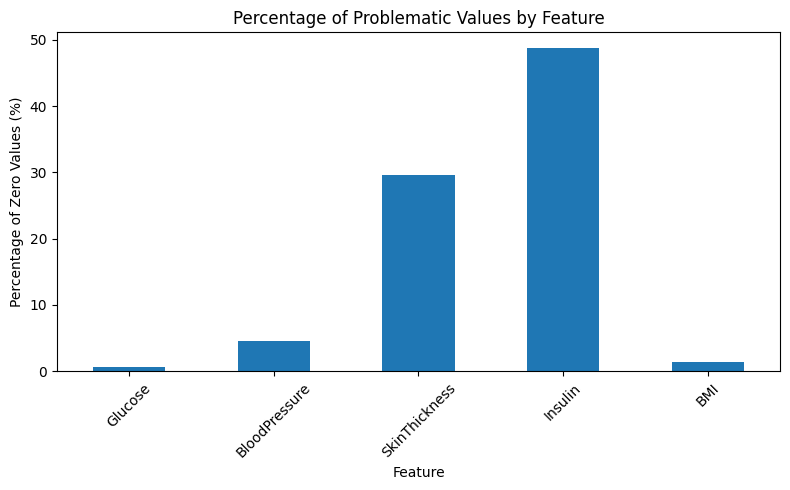

In [76]:
plt.figure(figsize=(8, 5))

zero_percentage.plot(kind="bar")

plt.title("Percentage of Problematic Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Percentage of Zero Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [77]:
df.duplicated().sum()

np.int64(0)

In [78]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [79]:
class_percentage = df["Outcome"].value_counts(normalize=True) * 100

class_percentage

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64

## Phase 1: Data Audit

The dataset contains 768 patient records and 9 columns, including 8 clinical
features and the target variable `Outcome`.

The dataset contains no explicit NaN values and no duplicate rows. However,
descriptive statistics revealed hidden missing/problematic measurements represented
by zero values.

The columns `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`
contain zero values that cannot represent valid clinical measurements and will
therefore be treated as missing values.

`Pregnancies = 0` is valid because a patient may have had no pregnancies.
Similarly, `Outcome = 0` is a valid target value representing a non-diabetic patient.

The target contains 500 non-diabetic patients (65.10%) and 268 diabetic patients
(34.90%), indicating moderate class imbalance. Therefore, accuracy alone will
not be sufficient for evaluating the models.

In [80]:
df_clean = df.copy()

In [81]:
missing_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df_clean[missing_columns] = df_clean[missing_columns].replace(0, np.nan)

In [82]:
df_clean[missing_columns].isna().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

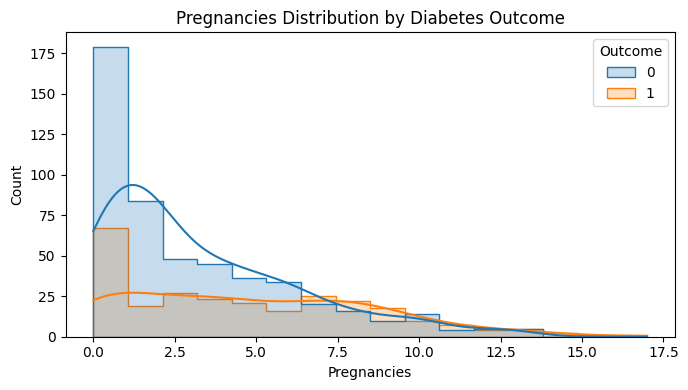

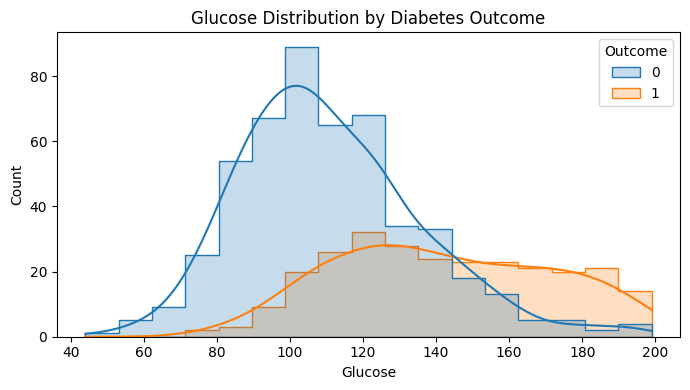

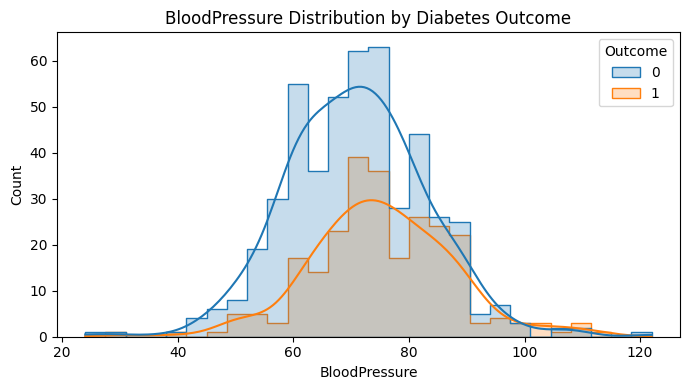

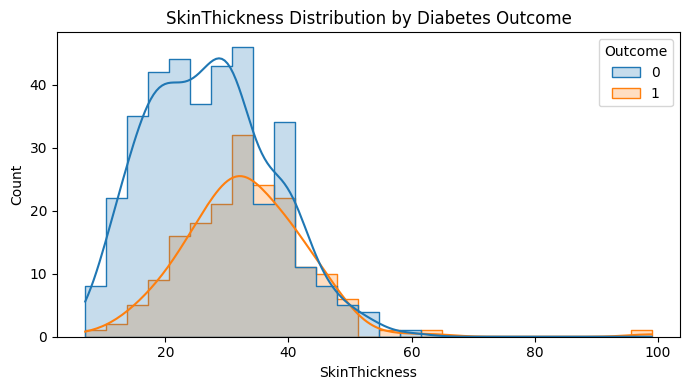

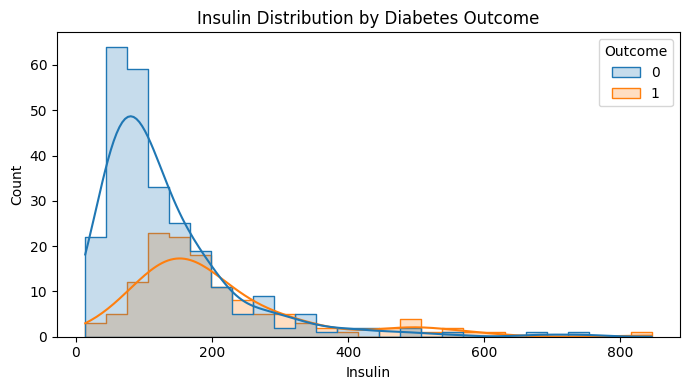

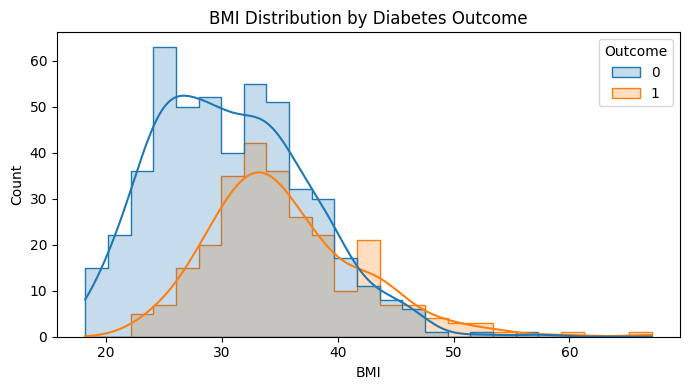

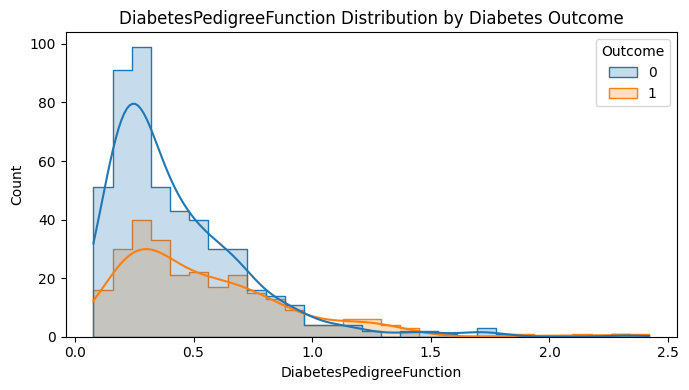

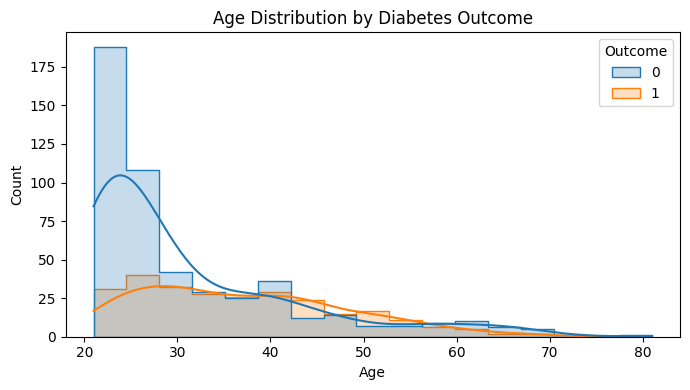

In [83]:
features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

for feature in features:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(
        data=df_clean,
        x=feature,
        hue="Outcome",
        kde=True,
        element="step"
    )
    
    plt.title(f"{feature} Distribution by Diabetes Outcome")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

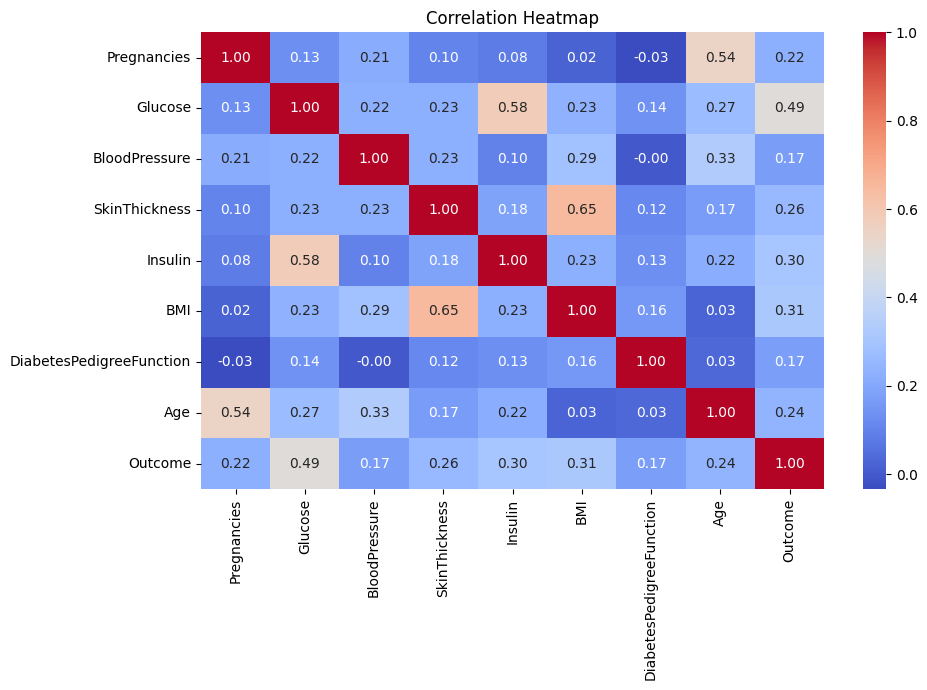

In [84]:
plt.figure(figsize=(10, 7))

correlation_matrix = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

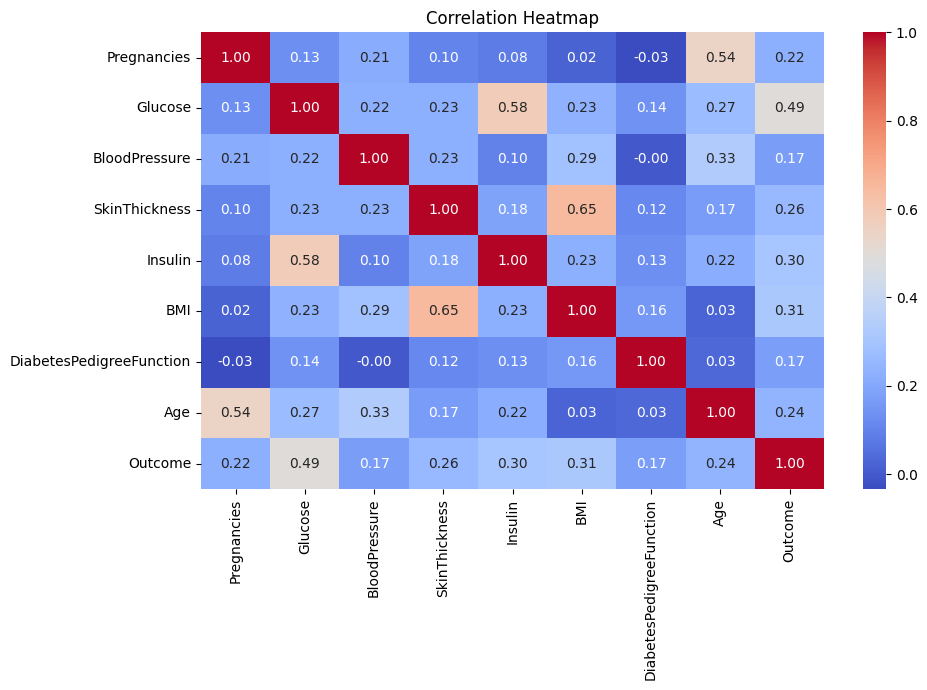

In [85]:
plt.figure(figsize=(10, 7))

correlation_matrix = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## EDA Observations

1. Glucose shows a noticeable difference between diabetic and non-diabetic
   patients, suggesting that it may be an important predictive feature.

2. BMI and Age also show differences between the two outcome groups and may
   contribute to diabetes-risk prediction.

3. Some features show considerable overlap between diabetic and non-diabetic
   patients, indicating that they may be weaker predictors individually.

4. The correlation analysis shows that the features do not all have the same
   relationship with the target, so using multiple clinical measurements
   together may provide better predictions than relying on a single feature.

5. Correlation measures linear relationships only; therefore, a feature with
   weak correlation may still be useful to nonlinear models such as Random
   Forest or XGBoost.

In [86]:
# Feature 1: Obesity indicator
df_clean["BMI_Obese"] = (df_clean["BMI"] >= 30).astype(int)

# Feature 2: High glucose indicator
df_clean["Glucose_High"] = (df_clean["Glucose"] >= 140).astype(int)

# Feature 3: Count of missing clinical measurements
df_clean["Missing_Measurement_Count"] = df_clean[
    ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
].isna().sum(axis=1)

In [87]:
df_clean[
    [
        "BMI",
        "BMI_Obese",
        "Glucose",
        "Glucose_High",
        "Missing_Measurement_Count"
    ]
].head(10)

,BMI,BMI_Obese,Glucose,Glucose_High,Missing_Measurement_Count
0,33.6,1,148.0,1,1
1,26.6,0,85.0,0,1
2,23.3,0,183.0,1,2
3,28.1,0,89.0,0,0
4,43.1,1,137.0,0,0
5,25.6,0,116.0,0,2
6,31.0,1,78.0,0,0
7,35.3,1,115.0,0,3
8,30.5,1,197.0,1,0
9,NaN,0,125.0,0,3


In [88]:
df_clean.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome', 'BMI_Obese',
       'Glucose_High', 'Missing_Measurement_Count'],
      dtype='object')

In [89]:
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

In [90]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [91]:
print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data: (614, 11)
Testing data : (154, 11)

Training target distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing target distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [92]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [93]:
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ))
])

In [94]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. I

In [95]:
y_pred = logistic_pipeline.predict(X_test)
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

In [96]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: D:\Python\python.exe -m pip install --upgrade pip


In [97]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [98]:
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

decision_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

In [99]:
models = {
    "Logistic Regression": logistic_pipeline,
    "KNN": knn_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline,
    "XGBoost": xgb_pipeline,
    "SVM": svm_pipeline
}

models

{'Logistic Regression': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('scaler', StandardScaler()),
                 ('model',
                  LogisticRegression(class_weight='balanced', max_iter=1000,
                                     random_state=42))]),
 'KNN': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('scaler', StandardScaler()),
                 ('model', KNeighborsClassifier())]),
 'Decision Tree': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('model',
                  DecisionTreeClassifier(class_weight='balanced',
                                         random_state=42))]),
 'Random Forest': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('model',
                  RandomForestClassifier(class_weight='balanced',
                                         random_state=42))]),
 'XGBoost': Pipeline(steps=[('imputer', SimpleImputer(strate

In [100]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [101]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [102]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [103]:
import pandas as pd
results = []

for name, model in models.items():
    
    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )
    
    results.append({
        "Model": name,
        
        "Accuracy Mean": cv_results["test_accuracy"].mean(),
        "Accuracy Std": cv_results["test_accuracy"].std(),
        
        "Precision Mean": cv_results["test_precision"].mean(),
        "Precision Std": cv_results["test_precision"].std(),
        
        "Recall Mean": cv_results["test_recall"].mean(),
        "Recall Std": cv_results["test_recall"].std(),
        
        "F1 Mean": cv_results["test_f1"].mean(),
        "F1 Std": cv_results["test_f1"].std(),
        
        "ROC-AUC Mean": cv_results["test_roc_auc"].mean(),
        "ROC-AUC Std": cv_results["test_roc_auc"].std(),
        
        "Train ROC-AUC": cv_results["train_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

results_df["Overfit Gap"] = (
    results_df["Train ROC-AUC"] -
    results_df["ROC-AUC Mean"]
)

results_df.sort_values(
    "ROC-AUC Mean",
    ascending=False
)

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,Train ROC-AUC,Overfit Gap
0,Logistic Regression,0.760536,0.023899,0.635081,0.033233,0.737984,0.049612,0.681988,0.034308,0.844614,0.017469,0.855541,0.010927
5,SVM,0.757310,0.027077,0.632042,0.045474,0.747730,0.030258,0.683130,0.019576,0.835923,0.018916,0.915056,0.079132
3,Random Forest,0.749167,0.026590,0.672677,0.053037,0.551163,0.034179,0.605236,0.037936,0.817652,0.027731,1.000000,0.182348
1,KNN,0.757297,0.019918,0.670992,0.044176,0.602547,0.032845,0.633827,0.026828,0.795620,0.039760,0.902474,0.106854
4,XGBoost,0.752432,0.033235,0.659428,0.065007,0.626246,0.038054,0.639131,0.027958,0.785467,0.028826,1.000000,0.214533
2,Decision Tree,0.690617,0.048421,0.561439,0.074316,0.551717,0.044707,0.555717,0.056399,0.658358,0.046582,1.000000,0.341642


In [104]:
results_df["Overfit Gap"] = (
    results_df["Train ROC-AUC"] - results_df["ROC-AUC Mean"]
)

results_df = results_df.sort_values(
    "ROC-AUC Mean",
    ascending=False
)

results_df

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,Train ROC-AUC,Overfit Gap
0,Logistic Regression,0.760536,0.023899,0.635081,0.033233,0.737984,0.049612,0.681988,0.034308,0.844614,0.017469,0.855541,0.010927
5,SVM,0.757310,0.027077,0.632042,0.045474,0.747730,0.030258,0.683130,0.019576,0.835923,0.018916,0.915056,0.079132
3,Random Forest,0.749167,0.026590,0.672677,0.053037,0.551163,0.034179,0.605236,0.037936,0.817652,0.027731,1.000000,0.182348
1,KNN,0.757297,0.019918,0.670992,0.044176,0.602547,0.032845,0.633827,0.026828,0.795620,0.039760,0.902474,0.106854
4,XGBoost,0.752432,0.033235,0.659428,0.065007,0.626246,0.038054,0.639131,0.027958,0.785467,0.028826,1.000000,0.214533
2,Decision Tree,0.690617,0.048421,0.561439,0.074316,0.551717,0.044707,0.555717,0.056399,0.658358,0.046582,1.000000,0.341642


In [105]:
from sklearn.model_selection import RandomizedSearchCV

logistic_params = {
    "model__C": np.logspace(-3, 2, 20),
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": ["balanced", None]
}

logistic_search = RandomizedSearchCV(
    estimator=logistic_pipeline,
    param_distributions=logistic_params,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

logistic_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': array([1.0000...00000000e+02]), 'model__class_weight': ['balanced', None], 'model__solver': ['liblinear', 'lbfgs']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... 

In [106]:
print("Best Parameters:")
print(logistic_search.best_params_)

print("\nBest CV ROC-AUC:")
print(logistic_search.best_score_)


Best Parameters:
{'model__solver': 'liblinear', 'model__class_weight': 'balanced', 'model__C': np.float64(0.06951927961775606)}

Best CV ROC-AUC:
0.846016057585825


In [107]:
svm_params = {
    "model__C": np.logspace(-2, 2, 20),
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto"],
    "model__class_weight": ["balanced", None]
}

svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_params,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

svm_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': array([1.0000...00000000e+02]), 'model__class_weight': ['balanced', None], 'model__gamma': ['scale', 'auto'], 'model__kernel': ['linear', 'rbf', ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation s

In [108]:
print("Best Parameters:")
print(svm_search.best_params_)

print("\nBest CV ROC-AUC:")
print(svm_search.best_score_)

Best Parameters:
{'model__kernel': 'linear', 'model__gamma': 'scale', 'model__class_weight': 'balanced', 'model__C': np.float64(0.026366508987303583)}

Best CV ROC-AUC:
0.8454346622369877


In [109]:
rf_params = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": ["balanced", "balanced_subsample", None]
}

rf_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=rf_params,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

rf_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': ['balanced', 'balanced_subsample', ...], 'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for t

In [110]:
print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest CV ROC-AUC:")
print(rf_search.best_score_)

Best Parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__class_weight': 'balanced_subsample'}

Best CV ROC-AUC:
0.8418743078626798


In [111]:
tuned_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Random Forest"
    ],
    "Best CV ROC-AUC": [
        logistic_search.best_score_,
        svm_search.best_score_,
        rf_search.best_score_
    ]
})

tuned_results = tuned_results.sort_values(
    "Best CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

tuned_results

,Model,Best CV ROC-AUC
0,Logistic Regression,0.846016
1,SVM,0.845435
2,Random Forest,0.841874


In [112]:
from sklearn.model_selection import cross_val_predict

final_model = logistic_search.best_estimator_

oof_prob = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF predictions generated:", len(oof_prob))

OOF predictions generated: 614


In [113]:
from sklearn.metrics import precision_score, recall_score

threshold_results = []

for threshold in np.arange(0.10, 0.71, 0.01):
    
    oof_pred = (oof_prob >= threshold).astype(int)
    
    recall = recall_score(y_train, oof_pred)
    precision = precision_score(y_train, oof_pred, zero_division=0)
    
    if recall >= 0.85:
        threshold_results.append({
            "Threshold": threshold,
            "Recall": recall,
            "Precision": precision
        })

threshold_df = pd.DataFrame(threshold_results)

threshold_df = threshold_df.sort_values(
    "Precision",
    ascending=False
).reset_index(drop=True)

threshold_df.head(10)

,Threshold,Recall,Precision
0,0.38,0.850467,0.544910
1,0.37,0.859813,0.536443
2,0.36,0.869159,0.531429
3,0.35,0.878505,0.520776
4,0.34,0.883178,0.513587
5,0.33,0.892523,0.512064
6,0.32,0.901869,0.505236
7,0.31,0.911215,0.501285
8,0.30,0.915888,0.497462
9,0.28,0.934579,0.490196


In [114]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

FINAL_THRESHOLD = 0.38

# Fit final tuned model on all training data
final_model.fit(X_train, y_train)

# Test probabilities
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply tuned threshold
test_pred = (test_prob >= FINAL_THRESHOLD).astype(int)

print("Accuracy :", accuracy_score(y_test, test_pred))
print("Precision:", precision_score(y_test, test_pred))
print("Recall   :", recall_score(y_test, test_pred))
print("F1 Score :", f1_score(y_test, test_pred))
print("ROC-AUC  :", roc_auc_score(y_test, test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

Accuracy : 0.7077922077922078
Precision: 0.5542168674698795
Recall   : 0.8518518518518519
F1 Score : 0.6715328467153284
ROC-AUC  : 0.8153703703703704

Confusion Matrix:
[[63 37]
 [ 8 46]]


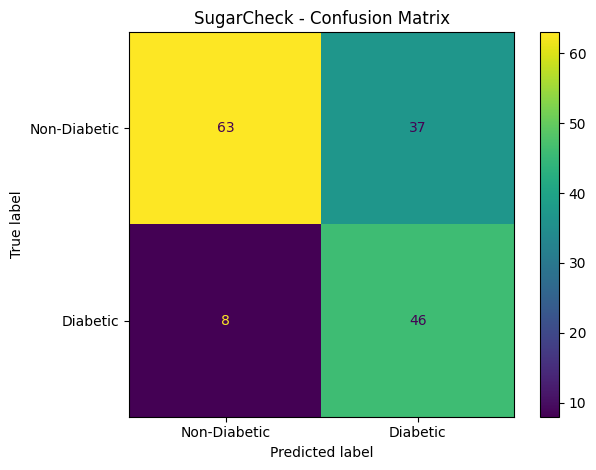

In [115]:
id="m8c4q2"
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot()
plt.title("SugarCheck - Confusion Matrix")
plt.tight_layout()
plt.show()

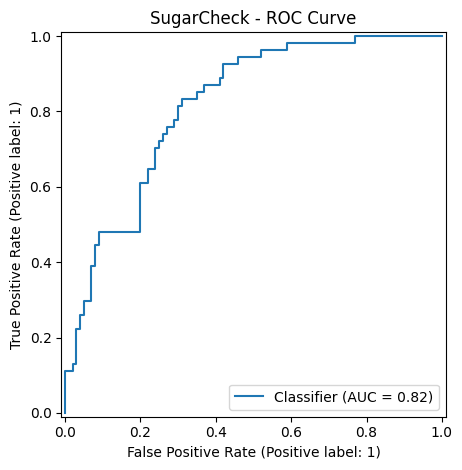

In [116]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    test_prob
)

plt.title("SugarCheck - ROC Curve")
plt.tight_layout()
plt.show()

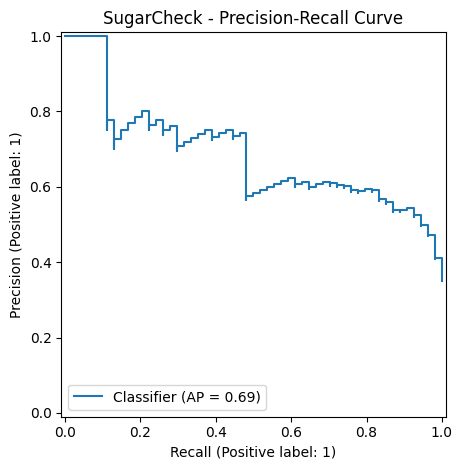

In [117]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_prob
)

plt.title("SugarCheck - Precision-Recall Curve")
plt.tight_layout()
plt.show()

## False Positive and False Negative Analysis

Using the tuned threshold of 0.38, the final model produced 8 false negatives
and 37 false positives on the unseen test set.

False negatives are particularly important in this project because they
represent diabetic patients who were classified as non-diabetic.

The model achieved 85.19% recall, meaning that it detected most of the
diabetic patients in the test set.

The higher number of false positives is an expected trade-off of lowering
the classification threshold to prioritize recall. In a screening context,
this can be preferable to missing a potentially diabetic patient.

However, SugarCheck is intended only as a screening aid and not as a
medical diagnosis.

In [118]:
feature_names = X_train.columns

coefficients = final_model.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    "Absolute Importance",
    ascending=False
)

feature_importance

,Feature,Coefficient,Absolute Importance
1,Glucose,0.878379,0.878379
5,BMI,0.402478,0.402478
0,Pregnancies,0.283643,0.283643
8,BMI_Obese,0.276044,0.276044
6,DiabetesPedigreeFunction,0.263599,0.263599
7,Age,0.173581,0.173581
10,Missing_Measurement_Count,0.147645,0.147645
9,Glucose_High,0.119007,0.119007
3,SkinThickness,0.054088,0.054088
4,Insulin,0.035966,0.035966


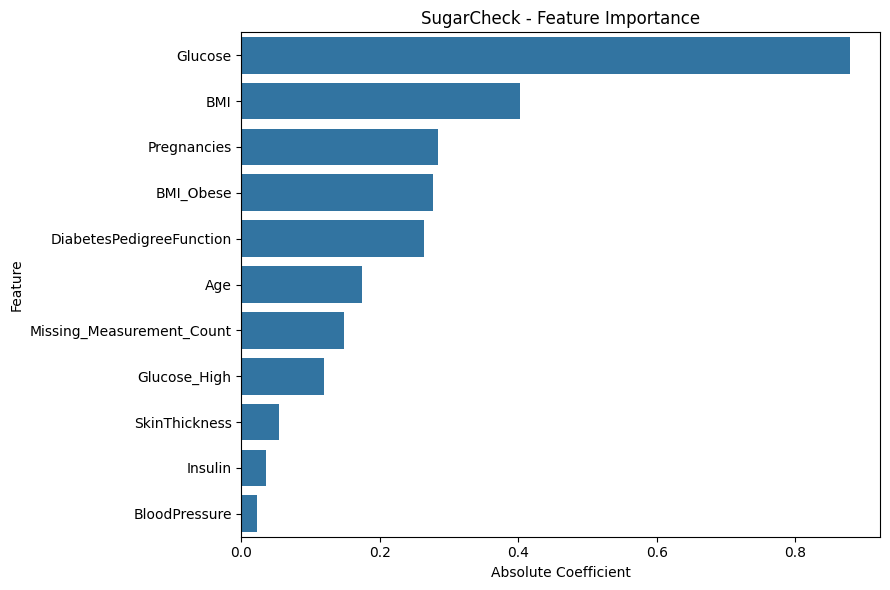

In [119]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Absolute Importance",
    y="Feature"
)

plt.title("SugarCheck - Feature Importance")
plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Final Conclusion

SugarCheck was developed as an early diabetes risk-screening system using
clinical and demographic features.

After data auditing, hidden missing values were identified and handled using
median imputation inside machine-learning pipelines to avoid data leakage.

Six classification models were compared using stratified 5-fold cross-validation.
Logistic Regression achieved the best tuned CV ROC-AUC of 0.8460 and was selected
as the final model.

Because the project prioritizes identifying diabetic patients, threshold tuning
was performed using out-of-fold predictions. A threshold of 0.38 achieved the
required recall of at least 85%.

On the unseen test set, the final model achieved:

- Accuracy: 70.78%
- Precision: 55.42%
- Recall: 85.19%
- F1 Score: 67.15%
- ROC-AUC: 81.54%

The model produced 8 false negatives and 37 false positives. The higher number
of false positives is an expected trade-off from prioritizing recall.

Glucose was the most influential feature in the final Logistic Regression model,
followed by BMI and Pregnancies.

SugarCheck should be considered a screening-support tool rather than a medical
diagnostic system.

## Limitations

1. The dataset is relatively small, containing 768 records.

2. The dataset represents a specific population, so the model may not
   generalize equally well to other populations.

3. Several clinical measurements contain missing/problematic values represented
   as zeros, requiring imputation.

4. The final model has a relatively high number of false positives after
   threshold tuning.

5. The model is intended for risk screening and should not be used as a
   substitute for professional medical diagnosis.

6. External validation on an independent dataset would be required before
   considering real-world clinical use.

In [120]:
print(logistic_search.best_score_)

0.846016057585825


In [121]:
print(logistic_search.best_score_)


0.846016057585825


In [122]:
final_model = logistic_search.best_estimator_

print(final_model)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=np.float64(0.06951927961775606),
                                    class_weight='balanced', max_iter=1000,
                                    random_state=42, solver='liblinear'))])


In [123]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    final_model,
    "models/sugarcheck_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [124]:
os.path.exists("models/sugarcheck_model.pkl")

True

In [125]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF predictions generated:", len(oof_prob))

OOF predictions generated: 614


In [126]:
import pandas as pd

df = pd.read_csv(r"D:\Jupyter\SugarCheck\diabetes_screening_data.csv")

print(df.shape)

(768, 9)


In [127]:
import numpy as np

df_clean = df.copy()

missing_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df_clean[missing_columns] = df_clean[missing_columns].replace(0, np.nan)

print(df_clean[missing_columns].isna().sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [128]:
df_clean["BMI_Obese"] = np.where(
    df_clean["BMI"].isna(),
    np.nan,
    (df_clean["BMI"] >= 30).astype(int)
)

df_clean["Glucose_High"] = np.where(
    df_clean["Glucose"].isna(),
    np.nan,
    (df_clean["Glucose"] >= 140).astype(int)
)

df_clean["Missing_Measurement_Count"] = df_clean[
    ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
].isna().sum(axis=1)

print(df_clean.shape)
print(df_clean.columns.tolist())

(768, 12)
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome', 'BMI_Obese', 'Glucose_High', 'Missing_Measurement_Count']


In [129]:
from sklearn.model_selection import train_test_split

X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (614, 11)
X_test : (154, 11)
y_train: (614,)
y_test : (154,)


In [130]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ))
])

print(logistic_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


In [131]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

decision_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

print("All 6 model pipelines created successfully.")

All 6 model pipelines created successfully.


In [132]:
models = {
    "Logistic Regression": logistic_pipeline,
    "KNN": knn_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline,
    "XGBoost": xgb_pipeline,
    "SVM": svm_pipeline
}

print("Models:", list(models.keys()))

Models: ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVM']


In [133]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("5-Fold Stratified Cross-Validation is ready.")

5-Fold Stratified Cross-Validation is ready.


In [134]:
cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Train ROC-AUC": scores["train_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print(cv_results_df.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC  \
0  Logistic Regression    0.7638     0.6399  0.7380  0.6845   0.8434   
1                  KNN    0.7557     0.6684  0.6025  0.6322   0.7949   
2        Decision Tree    0.6922     0.5621  0.5518  0.5554   0.6597   
3        Random Forest    0.7541     0.6801  0.5653  0.6159   0.8171   
4              XGBoost    0.7443     0.6479  0.5935  0.6169   0.7836   
5                  SVM    0.7606     0.6339  0.7524  0.6870   0.8360   

   Train ROC-AUC  
0         0.8551  
1         0.9022  
2         1.0000  
3         1.0000  
4         1.0000  
5         0.9141  


In [135]:
cv_results_df["Overfit Gap"] = (
    cv_results_df["Train ROC-AUC"] - cv_results_df["ROC-AUC"]
)

print(
    cv_results_df[
        ["Model", "ROC-AUC", "Train ROC-AUC", "Overfit Gap"]
    ].round(4)
)

                 Model  ROC-AUC  Train ROC-AUC  Overfit Gap
0  Logistic Regression   0.8434         0.8551       0.0116
1                  KNN   0.7949         0.9022       0.1073
2        Decision Tree   0.6597         1.0000       0.3403
3        Random Forest   0.8171         1.0000       0.1829
4              XGBoost   0.7836         1.0000       0.2164
5                  SVM   0.8360         0.9141       0.0781


In [136]:
from sklearn.model_selection import RandomizedSearchCV

print("Ready for hyperparameter tuning.")

Ready for hyperparameter tuning.


In [137]:
logistic_params = {
    "model__C": np.logspace(-3, 2, 20),
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": ["balanced", None]
}

logistic_search = RandomizedSearchCV(
    estimator=logistic_pipeline,
    param_distributions=logistic_params,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

logistic_search.fit(X_train, y_train)

print("Best Parameters:")
print(logistic_search.best_params_)

print("\nBest CV ROC-AUC:")
print(logistic_search.best_score_)

Best Parameters:
{'model__solver': 'liblinear', 'model__class_weight': 'balanced', 'model__C': np.float64(0.06951927961775606)}

Best CV ROC-AUC:
0.8453848283499447


In [138]:
svm_params = {
    "model__C": np.logspace(-2, 2, 20),
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto"],
    "model__class_weight": ["balanced", None]
}

svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_params,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

svm_search.fit(X_train, y_train)

print("Best Parameters:")
print(svm_search.best_params_)

print("\nBest CV ROC-AUC:")
print(svm_search.best_score_)

Best Parameters:
{'model__kernel': 'linear', 'model__gamma': 'scale', 'model__class_weight': 'balanced', 'model__C': np.float64(0.026366508987303583)}

Best CV ROC-AUC:
0.8453183831672204


In [139]:
rf_params = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": [
        "balanced",
        "balanced_subsample",
        None
    ]
}

rf_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=rf_params,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

rf_search.fit(X_train, y_train)

print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest CV ROC-AUC:")
print(rf_search.best_score_)

Best Parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__class_weight': 'balanced_subsample'}

Best CV ROC-AUC:
0.8422051495016613


In [140]:
tuned_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Random Forest"
    ],
    "Best CV ROC-AUC": [
        logistic_search.best_score_,
        svm_search.best_score_,
        rf_search.best_score_
    ]
})

print(tuned_results.round(4))

                 Model  Best CV ROC-AUC
0  Logistic Regression           0.8454
1                  SVM           0.8453
2        Random Forest           0.8422


In [141]:
final_model = logistic_search.best_estimator_

print(final_model)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=np.float64(0.06951927961775606),
                                    class_weight='balanced', max_iter=1000,
                                    random_state=42, solver='liblinear'))])


In [142]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Number of OOF predictions:", len(oof_prob))

Number of OOF predictions: 614


In [143]:
from sklearn.metrics import recall_score, precision_score

threshold_results = []

for threshold in np.arange(0.10, 0.71, 0.01):
    oof_pred = (oof_prob >= threshold).astype(int)

    recall = recall_score(y_train, oof_pred)
    precision = precision_score(
        y_train,
        oof_pred,
        zero_division=0
    )

    if recall >= 0.85:
        threshold_results.append({
            "Threshold": threshold,
            "Recall": recall,
            "Precision": precision
        })

threshold_df = pd.DataFrame(threshold_results)

threshold_df = threshold_df.sort_values(
    "Precision",
    ascending=False
).reset_index(drop=True)

print(threshold_df.head(10).round(4))

   Threshold  Recall  Precision
0       0.39  0.8505     0.5617
1       0.38  0.8551     0.5398
2       0.37  0.8551     0.5304
3       0.36  0.8598     0.5257
4       0.35  0.8785     0.5237
5       0.34  0.8832     0.5150
6       0.33  0.8972     0.5106
7       0.32  0.9019     0.5066
8       0.31  0.9065     0.5026
9       0.30  0.9159     0.4975


In [144]:
FINAL_THRESHOLD = 0.39

print("Final Threshold:", FINAL_THRESHOLD)

Final Threshold: 0.39


In [145]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Train final model on the training data
final_model.fit(X_train, y_train)

# Test probabilities
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply tuned threshold
test_pred = (test_prob >= FINAL_THRESHOLD).astype(int)

# Metrics
accuracy = accuracy_score(y_test, test_pred)
precision = precision_score(y_test, test_pred)
recall = recall_score(y_test, test_pred)
f1 = f1_score(y_test, test_pred)
roc_auc = roc_auc_score(y_test, test_prob)

print("Final Test Results")
print("------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

Final Test Results
------------------
Accuracy : 0.7078
Precision: 0.5542
Recall   : 0.8519
F1 Score : 0.6715
ROC-AUC  : 0.8137

Confusion Matrix:
[[63 37]
 [ 8 46]]


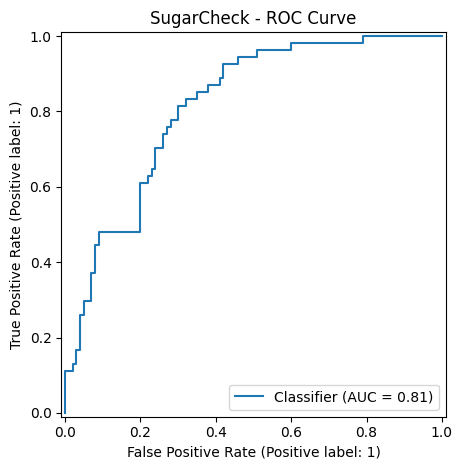

In [146]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    test_prob
)

plt.title("SugarCheck - ROC Curve")
plt.tight_layout()
plt.show()

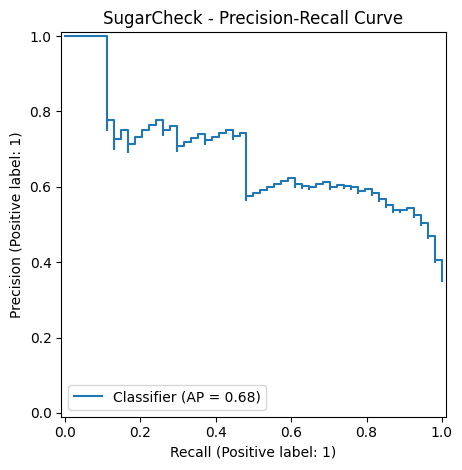

In [147]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_prob
)

plt.title("SugarCheck - Precision-Recall Curve")
plt.tight_layout()
plt.show()

In [148]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred
).ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)

True Negatives : 63
False Positives: 37
False Negatives: 8
True Positives  : 46


## False Positive and False Negative Analysis

The final model produced:

- True Negatives (TN): 63
- False Positives (FP): 37
- False Negatives (FN): 8
- True Positives (TP): 46

False negatives are especially important in SugarCheck because they represent
diabetic patients incorrectly classified as non-diabetic.

The model achieved a recall of 85.19%, meaning it identified most diabetic
patients in the unseen test set.

The higher number of false positives is an expected trade-off from lowering
the classification threshold to 0.39 and prioritizing recall.

In a screening application, accepting more false positives can be preferable
to missing potential diabetic cases. However, SugarCheck is only a screening
support tool and should not be considered a medical diagnosis.

In [149]:
feature_names = X_train.columns

coefficients = final_model.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
}).sort_values(
    "Absolute Importance",
    ascending=False
)

print(feature_importance.round(4))

                      Feature  Coefficient  Absolute Importance
1                     Glucose       0.8780               0.8780
5                         BMI       0.4138               0.4138
0                 Pregnancies       0.2819               0.2819
6    DiabetesPedigreeFunction       0.2609               0.2609
8                   BMI_Obese       0.2526               0.2526
7                         Age       0.1774               0.1774
10  Missing_Measurement_Count       0.1278               0.1278
9                Glucose_High       0.1226               0.1226
3               SkinThickness       0.0575               0.0575
4                     Insulin       0.0348               0.0348
2               BloodPressure       0.0205               0.0205


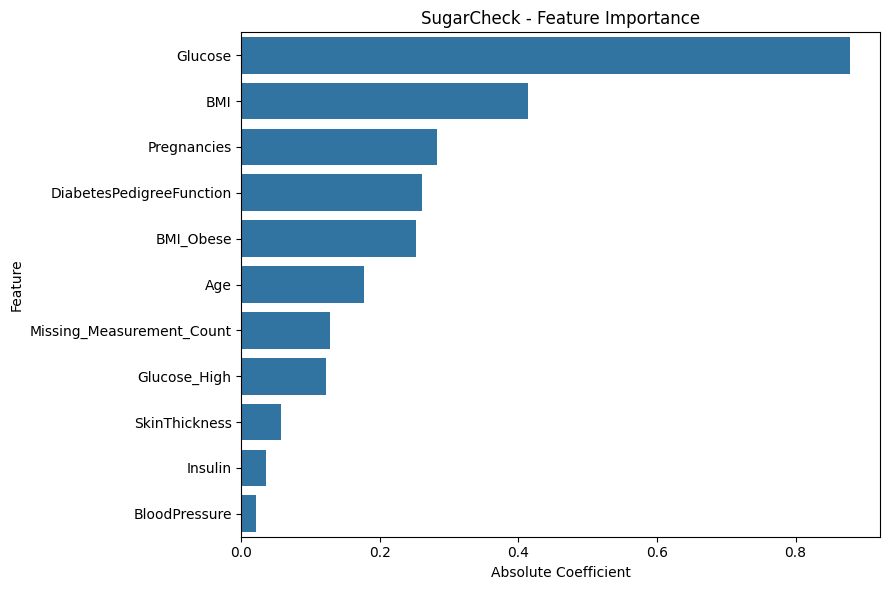

In [150]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Absolute Importance",
    y="Feature"
)

plt.title("SugarCheck - Feature Importance")
plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [151]:
import joblib
import os

model_path = r"D:\Jupyter\SugarCheck\models\sugarcheck_model.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print(model_path)

Model saved successfully!
D:\Jupyter\SugarCheck\models\sugarcheck_model.pkl


In [152]:
import joblib

model_path = r"D:\Jupyter\SugarCheck\models\sugarcheck_model.pkl"

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>
